# Lending Game — Part 9: Replaying the candidate rules on the real Round 1 market

In Round 1 we (**Ponzi & Co, lender 3**) submitted rule **R4** (Part 7) and made **€35.0M with a 55.6%
market share, 4th of 12 teams**. The winner made **€73.3M**.

The course's diagnostic file (`data/raw/Round1_Diagnostic_31.csv`) gives, for each of the 100,000 Round 1
applicants, **the two competitors' actual offers, the borrower's preference type and whether the
borrower defaulted**. With it, the profit any rule *would* have made in Round 1 is an **exact
counterfactual**, not a scenario: we replace our offer, rerun the borrower's choice with the existing
simulator (`src/simulator.py`), and book the observed default.

This notebook:

1. checks that the replay reproduces the course's outcome exactly;
2. describes the real Round 1 market (what the competitors actually did);
3. replays every Part 6 rule (B0, R1–R7, R4+C, R7+C) on it: how much did R4 leave on the table?
4. adds a new family **R8, "high quote"** (one high rate for everyone, or one per risk band);
5. adds **R4/R8 hybrids** (R4 where we compete, a high quote elsewhere, in both directions);
6. stress-tests the winners: what if Round 2's competitors stop leaving applicants uncontested?

The code is in `src/round_1_replay.py`. Everything here is **in hindsight**: the rules are tuned on
the market they are scored on. Section 4 checks this with cross-fitting, and section 7 asks what
would survive into Round 2.

## 0. Setup and check of the replay

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FIGURES_DIR
from src.pricing_rules import load_pricing_data, load_tuned_rules, rule_fixed_margin, pts
from src.round_1_replay import (BAND_LABELS, SITUATIONS, load_round1, check_replay, replay,
                               market_situation, risk_band, selection_by_situation, score_replay,
                               profit_by_band, profit_by_situation, calibration_by_band, oracle_rates,
                               rule_high_quote, rule_band_quotes, rule_switch, switch_profits,
                               make_folds, candidate_band_profits, best_per_band, crossfit_per_band,
                               stress_uncontested, breakeven_survival, undercut_high_quotes,
                               plot_situations, plot_competitor_rates, plot_rule_profits,
                               plot_rate_curves, plot_stress)
from src import model_plots as mp
from src import pricing_plots as pp

mp.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def save(fig, name):
    """Save a figure for report/round1_replay.md."""
    fig.savefig(FIGURES_DIR / name, dpi=150, bbox_inches="tight")


# Round 1 league table (course results): the winner's profit and ours (Ponzi & Co, lender 3).
WINNER_PROFIT = 73_310_618
OUR_REPORTED_PROFIT = 35_004_136

data = load_round1()
print(f"{len(data):,} Round 1 applicants, ids {data.index.min()} to {data.index.max()}")
display(data[["r1", "r2", "r3_submitted", "pref", "accepted", "default", "profit", "p_own",
              "p_public"]].head())

check = check_replay(data)
display(pd.Series({"acceptance matches the course's": f"{check['acceptance match']:.2%}",
                   "replayed profit": f"{check['replayed profit']:,.0f}",
                   "reported profit": f"{check['reported profit']:,.0f}",
                   "largest per-loan difference (EUR)": f"{check['largest loan difference']:.4f}"})
        .to_frame("check"))

100,000 Round 1 applicants, ids 1 to 100000


,r1,r2,r3_submitted,pref,accepted,default,profit,p_own,p_public
id,,,,,,,,,
1,0.039284,0.0559,0.041016,3,1,0,410.16000,0.022548,0.022196
2,NaN,NaN,0.120825,1,1,1,-10000.00000,0.081860,0.100561
3,0.043756,0.0739,0.041385,3,1,0,413.84998,0.022856,0.022461
4,0.115800,NaN,0.128803,3,1,0,1288.03000,0.088536,0.118094
5,0.159800,NaN,0.316272,1,0,0,NaN,0.128557,0.155296


,check
acceptance matches the course's,100.00%
replayed profit,"35,004,136"
reported profit,"35,004,136"
largest per-loan difference (EUR),0.0005


**The replay is exact.** Our submitted offers (R4), replayed against the real competitor offers with
each borrower's real type, give the course's outcome for **100% of applicants**, and our profit to
the euro (€35,004,136). The largest per-loan difference is €0.0005, which is rounding of the rates in
the file. From here on, every number is what a rule *would* have earned in Round 1.

## 1. The real Round 1 market

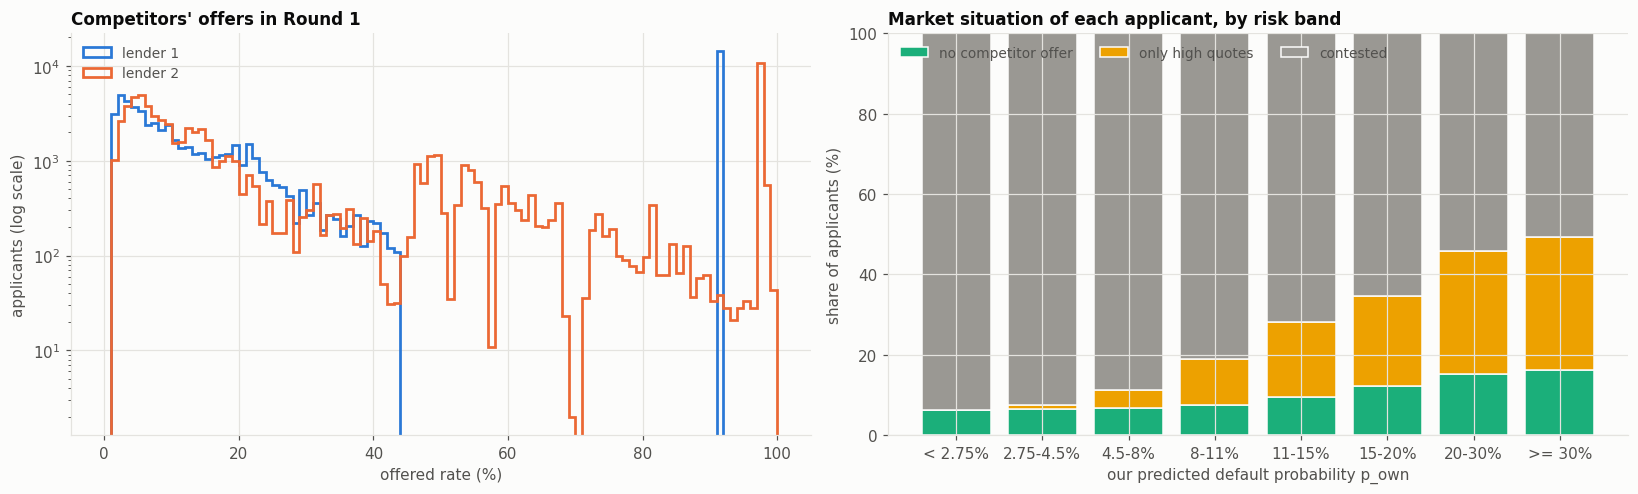

,no offer,most frequent rate,share quoted that rate,offers >= 90%,median offer
lender 1,34.39%,91.99%,14.21%,14.21%,12.81%
lender 2,25.19%,97.89%,10.53%,11.49%,14.40%


,applicants,"no offer, lender 1","no offer, lender 2",no competitor offer,only high quotes,contested,default rate
< 2.75%,"19,615",25.1%,24.8%,6.3%,0.0%,93.7%,1.4%
2.75-4.5%,"10,482",25.5%,25.7%,6.5%,0.9%,92.6%,3.6%
4.5-8%,"17,036",25.7%,24.8%,6.8%,4.4%,88.8%,6.8%
8-11%,"12,625",29.4%,25.4%,7.4%,11.4%,81.2%,9.4%
11-15%,"18,745",38.9%,25.0%,9.5%,18.6%,71.9%,13.2%
15-20%,"10,519",46.8%,25.3%,12.2%,22.5%,65.3%,17.3%
20-30%,"9,158",58.5%,25.9%,15.3%,30.6%,54.1%,23.1%
>= 30%,"1,820",61.6%,26.5%,16.2%,33.2%,50.6%,30.8%


no competitor offer     8754
only high quotes       11541
contested              79705


In [2]:
situation = market_situation(data)
band = risk_band(data)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
plot_competitor_rates(data, axes[0])
plot_situations(data, axes[1])
fig.tight_layout()
save(fig, "fig18_round1_market.png")
plt.show()

overview = pd.DataFrame({
    f"lender {k}": {"no offer": data[f"r{k}"].isna().mean(),
                    "most frequent rate": data[f"r{k}"].mode()[0],
                    "share quoted that rate": (data[f"r{k}"] == data[f"r{k}"].mode()[0]).mean(),
                    "offers >= 90%": (data[f"r{k}"] >= 0.9).mean(),
                    "median offer": data[f"r{k}"].median()} for k in (1, 2)}).T
display(overview.style.format("{:.2%}"))

by_band = pd.DataFrame({"applicants": band.value_counts(sort=False),
                        "no offer, lender 1": data["r1"].isna().groupby(band, observed=False).mean(),
                        "no offer, lender 2": data["r2"].isna().groupby(band, observed=False).mean()})
by_band = by_band.join(pd.crosstab(band, situation, normalize="index"))
by_band["default rate"] = data["default"].groupby(band, observed=False).mean()
display(by_band.style.format({c: "{:,}" if c == "applicants" else "{:.1%}" for c in by_band.columns}))
print(situation.value_counts().reindex(SITUATIONS).to_string())

**The competitors did not price like any of our Part 7 scenarios.** Each competitor slot is a mixture
of teams (four teams per slot, drawn at random per loan), and the mixture shows three behaviours:

* **No offer at all:** lender 1 made no offer to **34.4%** of applicants and lender 2 to **25.2%**.
  For lender 2 this share is flat across risk bands (25%). For lender 1 it rises with risk, from 25%
  for the safest to 62% for $p_{own} \ge 30\%$.
* **A fixed high quote:** lender 1 quoted exactly **91.99%** to 14.2% of applicants, lender 2
  **97.89%** to 10.5%. These quotes do not depend on risk: a team quoting one very high rate to
  everyone.
* **A "real" pricing curve** for the rest (median offers 12.8% and 14.4%).

**One applicant in five was uncontested:**

* **8,754 (8.8%)** got no competitor offer at all;
* **11,541 (11.5%)** got only high quotes (every competitor offer at or above 90%).

Under the game rules, such borrowers take our offer at any rate up to 100%. **The uncontested share
rises with risk**: 6% of the safest applicants, against 46–49% of those with $p_{own} \ge 20\%$.
Only 6% of the safest applicants are uncontested, but that is still 1,229 borrowers with a 1.5% default rate.

In [3]:
sel = selection_by_situation(data)
overall = pd.DataFrame({"p": data["p_own"], "d": data["default"]}).groupby(situation, observed=False)
overall = overall.agg(applicants=("d", "size"), mean_p_own=("p", "mean"), default_rate=("d", "mean"))
overall["gap"] = overall["default_rate"] - overall["mean_p_own"]
display(overall.style.format({"applicants": "{:,}", "mean_p_own": "{:.2%}", "default_rate": "{:.2%}",
                              "gap": "{:+.2%}"}))
display(sel["gap"].unstack().style.format("{:+.2%}"))

,applicants,mean_p_own,default_rate,gap
situation,,,,
no competitor offer,"8,754",12.53%,13.58%,+1.05%
only high quotes,"11,541",16.86%,18.46%,+1.60%
contested,"79,705",8.67%,8.32%,-0.36%


situation,no competitor offer,only high quotes,contested
p_own,,,
< 2.75%,+0.17%,+30.92%,+0.05%
2.75-4.5%,-0.22%,+7.08%,-0.05%
4.5-8%,+1.75%,+3.99%,+0.34%
8-11%,-0.28%,+2.74%,-0.44%
11-15%,+2.08%,+1.47%,-0.39%
15-20%,+1.25%,+1.57%,-0.85%
20-30%,+2.82%,+0.44%,-2.37%
>= 30%,-6.21%,+1.17%,-7.42%


**Are the uncontested borrowers worse than our model says?** Gap = observed default rate − mean $p_{own}$:

* **Contested:** −0.4 point. Our model is right, slightly pessimistic.
* **No competitor offer:** **+1.1 points** (13.6% observed against 12.5% predicted).
* **Only high quotes:** **+1.6 points** (18.5% against 16.9%).

So the competitors' refusals carry some information our model lacks (their own signals): the
borrowers they leave alone are somewhat riskier than $p_{own}$ says. But the effect is small, 1–2
points of default. At a rate of 90%, a borrower who repays earns €9,000 and one who defaults costs
€10,000, so a 1.6-point surprise costs about €300 per loan, against a margin of several thousand
euros.

## 2. Replaying the Part 6 rules

In [4]:
train = load_pricing_data("train")       # load_tuned_rules needs it (only R7 uses it)
rules = load_tuned_rules(train)
PART6 = ["B0", "R1", "R2", "R3", "R4", "R5", "R6", "R7", "R4+C", "R7+C"]
rates = {name: rules[name](data) for name in PART6}

same = np.allclose(rates["R4"].fillna(-1), data["r3_submitted"].fillna(-1), atol=1e-6)
print(f"rebuilt R4 = our submitted offers: {same}")

table, profits = score_replay(rates, data)
cols = ["profit", "n_loans", "share", "profit_per_loan", "avg_rate", "default_rate_won", "gap",
        "profit_contested", "profit_no competitor offer", "profit_only high quotes"]
fmt = {"profit": "{:+,.0f}", "n_loans": "{:,.0f}", "share": "{:.1%}", "profit_per_loan": "{:+,.0f}",
       "avg_rate": "{:.2%}", "default_rate_won": "{:.2%}", "gap": "{:+.2%}",
       "profit_contested": "{:+,.0f}", "profit_no competitor offer": "{:+,.0f}",
       "profit_only high quotes": "{:+,.0f}"}
display(table.loc[PART6, cols].sort_values("profit", ascending=False).style.format(fmt))

rebuilt R4 = our submitted offers: True


,profit,n_loans,share,profit_per_loan,avg_rate,default_rate_won,gap,profit_contested,profit_no competitor offer,profit_only high quotes
rule,,,,,,,,,,
R4,"+35,004,134","55,568",55.6%,+630,21.52%,11.37%,+0.95%,"+16,445,012","+6,721,385","+11,837,737"
R2,"+31,535,635","52,616",52.6%,+599,21.40%,11.57%,+1.13%,"+14,831,358","+6,151,440","+10,552,837"
R7,"+24,250,313","57,905",57.9%,+419,19.40%,11.77%,+1.09%,"+12,966,341","+4,273,058","+7,010,914"
R3,"+23,477,053","56,910",56.9%,+413,19.52%,11.91%,+1.10%,"+12,761,643","+4,145,159","+6,570,251"
R5,"+19,571,479","52,596",52.6%,+372,20.71%,13.28%,+1.01%,"+11,483,432","+3,436,903","+4,651,144"
R6,"+13,015,144","51,668",51.7%,+252,19.67%,13.66%,+0.86%,"+8,478,455","+2,440,528","+2,096,161"
R1,"+12,971,399","53,449",53.4%,+243,19.40%,13.58%,+0.93%,"+9,362,509","+1,988,615","+1,620,274"
R4+C,"+9,265,355","35,808",35.8%,+259,9.86%,6.39%,+0.73%,"+6,684,981","+1,467,099","+1,113,274"
R7+C,"+5,535,615","29,177",29.2%,+190,7.81%,5.36%,+0.77%,"+4,739,530","+733,047","+63,039"


The rebuilt R4 gives exactly our submitted offers.

**R4 was the best of the ten Part 6 rules on the real market:** €35.0M, ahead of R2 (€31.5M), R7
(€24.3M) and R3 (€23.5M). B0 (break-even) loses €2.7M: the winner's curse is real.

**Part 7's decision was right among the candidates, for the reason Part 7 gave:**

* R4 and R4+C differ only on the riskiest third of the applicants: R4 quotes them high rates, R4+C refuses them.
  On the real market that difference was **worth €25.7M** (R4 €35.0M against R4+C €9.3M).
* Part 7 argued that quoting the risky applicants high instead of refusing them keeps a cheap option
  in case competitors stay away from them. The competitors did stay away: lender 1 refused up to 62%
  of the riskiest applicants.

**More than half of R4's profit came from one fifth of the applicants:**

* **€18.6M (53%)** from the 20,295 uncontested applicants (€6.7M with no competitor offer, €11.8M
  with only high quotes);
* **€16.4M** from the 79,705 contested applicants.

The rules with a cutoff (R4+C, R7+C) gave up most of that pool, which is why they finish last
among the rules that make money.

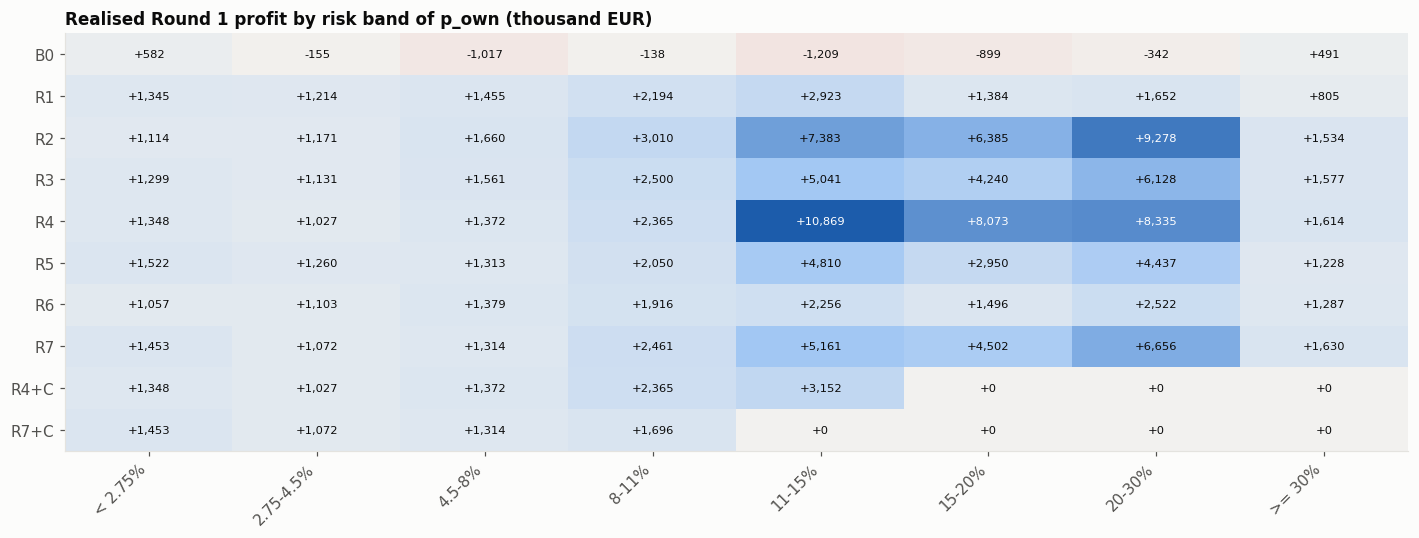

,actual borrower types,expected over the 3 types,difference
rule,,,
B0,"-2,686,210","-2,791,696","+105,487"
R1,"+12,971,399","+12,970,713",+686
R2,"+31,535,635","+31,751,230","-215,595"
R3,"+23,477,053","+23,867,020","-389,968"
R4,"+35,004,134","+35,040,432","-36,298"
R5,"+19,571,479","+19,680,435","-108,956"
R6,"+13,015,144","+12,691,359","+323,785"
R7,"+24,250,313","+24,668,657","-418,344"
R4+C,"+9,265,355","+9,342,526","-77,171"


In [5]:
bands_profit = profit_by_band(profits, data).loc[PART6]
fig, ax = plt.subplots(figsize=(13, 5))
pp.plot_heatmap(bands_profit, ax, "Realised Round 1 profit by risk band of p_own (thousand EUR)")
fig.tight_layout()
plt.show()

luck = pd.DataFrame({"actual borrower types": table.loc[PART6, "profit"],
                     "expected over the 3 types": score_replay(rates, data, mode="expected")[0]["profit"]})
luck["difference"] = luck.iloc[:, 0] - luck.iloc[:, 1]
display(luck.style.format("{:+,.0f}"))

**By risk band**, R4's profit comes mostly from the bands above 11%, where it quotes 17–19 points over
break-even and where most of the uncontested applicants are.

**Luck of the borrower types was negligible.** Averaging over the three preference types instead of
using the real ones changes R4's profit by only **−€36k** (0.1%). The other rules move by at most
±€0.4M. We did not lose Round 1 to bad luck.

In [6]:
loans_r4, _ = replay(data["r3_submitted"], data)
calib = calibration_by_band(data, loans_r4)
display(calib.style.format({"applicants": "{:,}", "loans won": "{:,.0f}"} |
                           {c: "{:.2%}" for c in calib.columns if c not in ("applicants", "loans won")}))
overall_calib = pd.Series({"mean p_own, all applicants": data["p_own"].mean(),
                           "default rate, all applicants": data["default"].mean(),
                           "mean p_own, loans won": table.loc["R4", "avg_p_won"],
                           "default rate, loans won": table.loc["R4", "default_rate_won"]})
display(overall_calib.to_frame("R4, Round 1").style.format("{:.2%}"))

,applicants,mean p_own (all),default rate (all),loans won,gap (all),mean p_own (won),default rate (won),gap (won)
band,,,,,,,,
< 2.75%,"19,615",1.29%,1.36%,"9,727",0.07%,1.33%,1.68%,0.35%
2.75-4.5%,"10,482",3.59%,3.60%,"5,715",0.00%,3.59%,3.81%,0.22%
4.5-8%,"17,036",6.16%,6.76%,"9,411",0.59%,6.24%,7.54%,1.31%
8-11%,"12,625",9.48%,9.42%,"7,922",-0.06%,9.41%,10.05%,0.64%
11-15%,"18,745",12.98%,13.17%,"9,567",0.19%,13.01%,14.93%,1.91%
15-20%,"10,519",17.31%,17.26%,"5,955",-0.05%,17.38%,18.79%,1.41%
20-30%,"9,158",23.86%,23.14%,"6,279",-0.72%,23.87%,24.86%,0.99%
>= 30%,"1,820",35.19%,30.82%,992,-4.37%,34.59%,32.56%,-2.03%


,"R4, Round 1"
"mean p_own, all applicants",9.96%
"default rate, all applicants",9.95%
"mean p_own, loans won",10.42%
"default rate, loans won",11.37%


**Our model was well calibrated; what hurt was the winner's curse.**

* **On all 100,000 applicants,** the mean $p_{own}$ is **9.96%** and the observed default rate
  **9.95%**. Every band is within 0.7 point, except $p_{own} \ge 30\%$, where we *over*-predict by
  4.4 points (1,820 applicants).
* **On the 55,568 loans R4 won,** we predicted 10.4% and observed **11.4%**: a winner's-curse gap of
  **+0.95 point**. The gap is largest in the 11–15% band (**+1.9 points**) and the 15–20% band
  (+1.4 points).

So the "1.5–2 point under-prediction above 11%" seen on our loans is **selection, not
miscalibration**. Among the applicants we won, the competitors had already priced away the better
ones. Retraining on 200k loans will not remove it, since it comes from what the competitors know.
A margin has to pay for it.

## 3. What R4 left on the table in the contested market

In [7]:
# The applicants with at least one competitor offer below 90%: what could a competitive
# rule have earned there, at best? One flat margin per R4 decile, chosen in hindsight.
edges = rules["R4"].params["edges"]
contested = data[situation == "contested"]
margins = pts(0, 0.60, 0.0025)
cand = {m: rule_fixed_margin(contested, m, floor=0.005) for m in margins}
cand["R4"] = rules["R4"](contested)
bp_contested = candidate_band_profits(contested, cand, edges)

best_contested = best_per_band(bp_contested.drop(columns="R4")).rename(
    columns={"best": "best margin", "profit": "best profit"})
best_contested.insert(0, "p_own from", [0.0] + list(edges))
best_contested["R4 margin"] = rules["R4"].params["margins"]
best_contested["R4 profit"] = bp_contested["R4"]
best_contested["left on the table"] = best_contested["best profit"] - best_contested["R4 profit"]
display(best_contested.style.format({"p_own from": "{:.2%}", "best margin": "{:.2%}", "R4 margin": "{:.2%}",
                                     "best profit": "{:+,.0f}", "R4 profit": "{:+,.0f}",
                                     "left on the table": "{:+,.0f}"}))
print(f"contested applicants: {len(contested):,}; R4 earned {bp_contested['R4'].sum():+,.0f}, "
      f"the best margin per decile {best_contested['best profit'].sum():+,.0f}")

,p_own from,best margin,best profit,R4 margin,R4 profit,left on the table
band,,,,,,
0,0.00%,2.75%,"+745,537",1.75%,"+478,588","+266,948"
1,1.22%,2.50%,"+870,824",1.75%,"+691,699","+179,125"
2,2.75%,3.50%,"+1,133,580",2.00%,"+911,522","+222,058"
3,4.47%,4.75%,"+738,220",3.17%,"+659,090","+79,131"
4,6.45%,5.00%,"+1,332,416",3.17%,"+1,247,608","+84,809"
5,8.69%,32.00%,"+2,311,308",3.17%,"+1,273,937","+1,037,370"
6,11.10%,31.50%,"+3,955,530",16.88%,"+2,988,532","+966,998"
7,13.28%,30.50%,"+2,740,963",16.88%,"+2,111,197","+629,766"
8,15.42%,27.00%,"+3,702,251",19.38%,"+3,106,608","+595,643"


contested applicants: 79,705; R4 earned +16,445,012, the best margin per decile +20,793,054


On the 79,705 contested applicants (at least one competitor offer below 90%), the best fixed margin
per R4 decile, chosen in hindsight, earns **€20.8M against R4's €16.4M: +€4.3M**.

* **Safe deciles ($p_{own} < 8.7\%$): R4's margins were too low.** The best margins are 2.5–5 points
  against R4's 1.75–3.2 points. That is worth +€0.8M across the five deciles.
* **Deciles 6–10 ($p_{own} \ge 8.7\%$): much higher margins paid even on contested applicants.** The
  best is 25.5–32 points (R4: 3.2 points in decile 6, 17–19 above). That is +€3.5M. A contested
  applicant can still have a competitor offer at 40–90%, and a high margin wins those.

Even fully exploited with hindsight, the contested market was worth only about €21M. **The money was
elsewhere.**

## 4. R8: a high quote

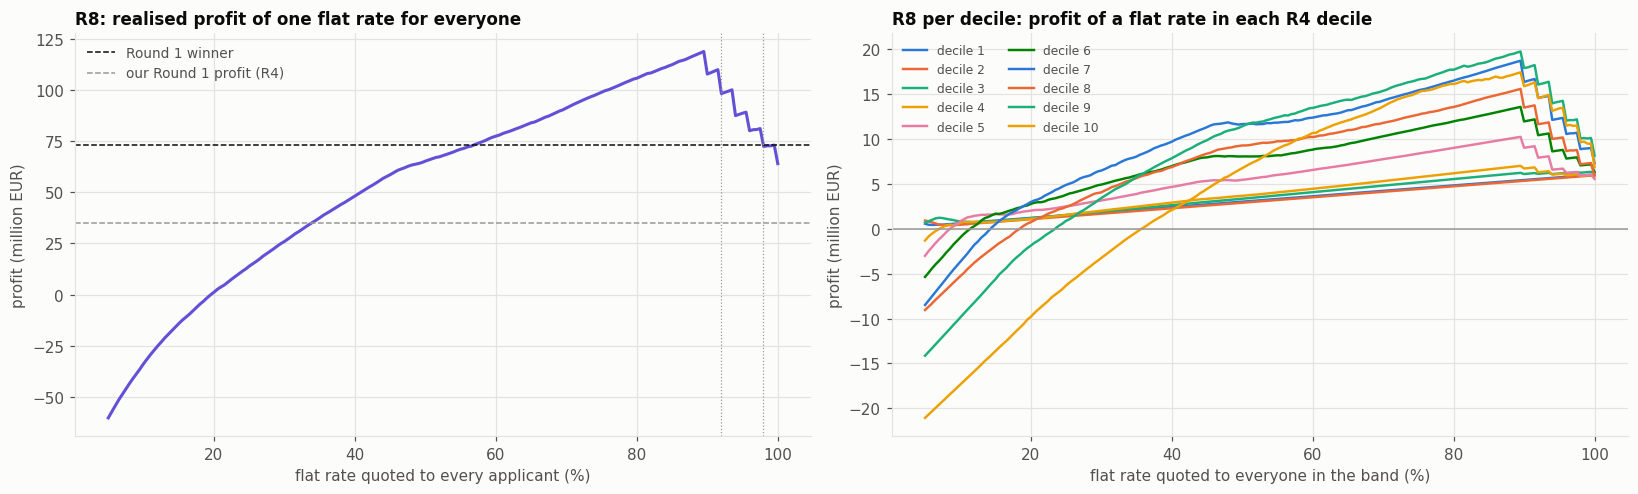

best single flat rate: 89.5%, profit +118,926,850


,0.500000,0.700000,0.800000,0.850000,0.890000,0.895000,0.900000,0.915000,0.920000,0.950000,0.975000,0.980000,1.000000
profit,"+65,300,000","+91,250,000","+105,850,000","+112,469,500","+118,178,000","+118,926,850","+107,884,000","+110,048,350","+98,326,800","+88,731,500","+81,211,500","+72,389,600","+64,050,000"


In [8]:
# R8: one flat rate for everyone. Profit for every rate from 5% to 100%, by R4 decile.
flat_grid = pts(0.05, 1.0, 0.005)
cand_flat = {r: rule_high_quote(data, r) for r in flat_grid}
bp_flat = candidate_band_profits(data, cand_flat, edges)
total_flat = bp_flat.sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
axes[0].plot(100 * np.asarray(total_flat.index), total_flat / 1e6, color=pp.LENDER_COLORS[3])
axes[0].axhline(WINNER_PROFIT / 1e6, color=mp.INK, lw=1, ls="--", label="Round 1 winner")
axes[0].axhline(OUR_REPORTED_PROFIT / 1e6, color=mp.REFERENCE, lw=1, ls="--", label="our Round 1 profit (R4)")
for q in (91.99, 97.89):
    axes[0].axvline(q, color=mp.REFERENCE, lw=0.8, ls=":")
axes[0].set_xlabel("flat rate quoted to every applicant (%)")
axes[0].set_ylabel("profit (million EUR)")
axes[0].set_title("R8: realised profit of one flat rate for everyone")
axes[0].legend(labelcolor=mp.INK_SECONDARY)
curves = bp_flat.copy()
curves.index = [f"decile {b + 1}" for b in curves.index]
plot_rate_curves(curves, axes[1], "R8 per decile: profit of a flat rate in each R4 decile")
fig.tight_layout()
save(fig, "fig19_round1_high_quote.png")
plt.show()

best_flat = total_flat.idxmax()
print(f"best single flat rate: {best_flat:.1%}, profit {total_flat.max():+,.0f}")
display(total_flat.loc[[0.5, 0.7, 0.8, 0.85, 0.89, 0.895, 0.9, 0.915, 0.92, 0.95, 0.975, 0.98, 1.0]]
        .to_frame("profit").T.style.format("{:+,.0f}"))

**One flat rate of 89.5% for every applicant would have made €118.9M.** That is 3.4 times our profit
and 1.6 times the winner's.

* **Why 89.5% exactly:** it is just under **91.99% − 2 points**. A borrower who prefers lender 1 sees
  lender 1's 91.99% quote as 89.99%, so 89.5% still beats it. At 90.0% that borrower goes to lender
  1, and profit drops to €107.9M.
* **The curve:**
  * profit rises steadily up to 89.5%: €65M at 50%, €106M at 80%;
  * it falls in steps above, as each high-quote competitor wins its applicants back;
  * at 100% we win only the applicants with no competitor offer, and that alone is **€64M**, as
    much as the winner made.
* **R8 wins almost nothing contested** (€0.2M). All of its profit comes from the 20% of applicants
  with no competitor offer or only high quotes.

In [9]:
# R8 per band: the best flat rate in each R4 decile, in sample and cross-fitted
# (chosen on one half of the applicants, scored on the other half, then swapped).
folds = make_folds(data, n_folds=2)
bp_flat_folds = candidate_band_profits(data, cand_flat, edges, folds=folds)
crossfit_total, crossfit_choice = crossfit_per_band(bp_flat_folds)

per_band = best_per_band(bp_flat).rename(columns={"best": "best rate", "profit": "best profit"})
per_band.insert(0, "p_own from", [0.0] + list(edges))
per_band["profit at the single best rate"] = bp_flat[best_flat]
per_band["chosen on half 1"] = crossfit_choice.xs(1, level=0)   # chosen on fold 0, used on fold 1
per_band["chosen on half 2"] = crossfit_choice.xs(0, level=0)
display(per_band.style.format({"p_own from": "{:.2%}", "best rate": "{:.1%}", "best profit": "{:+,.0f}",
                               "profit at the single best rate": "{:+,.0f}",
                               "chosen on half 1": "{:.1%}", "chosen on half 2": "{:.1%}"}))

flat_folds = bp_flat_folds.groupby(level=0).sum()
single_cf = sum(flat_folds.loc[k, flat_folds.drop(index=k).sum().idxmax()] for k in flat_folds.index)
display(pd.DataFrame({"in sample": [total_flat.max(), per_band["best profit"].sum()],
                      "cross-fitted": [single_cf, crossfit_total]},
                     index=["R8, one flat rate", "R8, one flat rate per decile"]).style.format("{:+,.0f}"))

,p_own from,best rate,best profit,profit at the single best rate,chosen on half 1,chosen on half 2
band,,,,,,
0,0.00%,100.0%,"+6,010,000","+5,377,900",100.0%,100.0%
1,1.22%,100.0%,"+5,930,000","+5,297,400",100.0%,100.0%
2,2.75%,99.5%,"+6,317,150","+6,204,550",99.5%,89.5%
3,4.47%,89.5%,"+6,984,400","+6,984,400",89.5%,89.5%
4,6.45%,89.5%,"+10,210,250","+10,210,250",89.5%,89.5%
5,8.69%,89.5%,"+13,540,950","+13,540,950",89.5%,89.5%
6,11.10%,89.5%,"+18,675,100","+18,675,100",89.5%,89.5%
7,13.28%,89.5%,"+15,543,200","+15,543,200",89.5%,89.5%
8,15.42%,89.5%,"+19,703,700","+19,703,700",89.5%,89.5%


,in sample,cross-fitted
"R8, one flat rate","+118,926,850","+118,926,850"
"R8, one flat rate per decile","+120,304,150","+120,142,800"


**One flat rate per R4 decile adds little:** €120.3M against €118.9M.

* **The safest deciles prefer 99.5–100%.** Below 4.5% risk, almost no applicant gets only high
  quotes, so undercutting 91.99% gains nothing there.
* **Every other decile chooses 89.5%.**

**Cross-fitting confirms it is not overfitting.** Choosing the rate on one half of the applicants and
scoring it on the other half gives:

* **€118.9M for the single flat rate**, the same as in sample: both halves choose 89.5%;
* **€120.1M for one rate per decile**, against €120.3M in sample.

The noise of the defaults is not driving the result. What drives it is the *structure* of the Round 1
market: the uncontested 20% and the exact level of the competitors' high quotes.

## 5. R4/R8 hybrids

In [10]:
# R4/R8 hybrids with one switch point at an R4 decile edge, in both directions:
#   "R4|R8": R4 on the safe side of the switch, a flat high quote on the risky side;
#   "R8|R4": the flat high quote on the safe side, R4 on the risky side.
# Every flat rate of the grid is tried as the high quote (exact per band, no extra replay).
bp_r4 = candidate_band_profits(data, {"R4": rates["R4"]}, edges)["R4"]
switch = pd.concat({"R4|R8 (high quote above)": switch_profits(bp_r4, bp_flat, edges, "above"),
                    "R8|R4 (high quote below)": switch_profits(bp_r4, bp_flat, edges, "below")}, axis=1)
display(switch.style.format("{:.1%}", subset=[c for c in switch.columns if c[1] == "best high quote"],
                            na_rep="-")
        .format("{:+,.0f}", subset=[c for c in switch.columns if c[1] in ("profit", "of which base rule")])
        .format_index("{:.2%}"))

Two directions, with one switch point at each R4 decile edge:

* **R4|R8**: R4 below the switch, a flat high quote above (the plan's "compete on the safe, quote high on the risky");
* **R8|R4**: the high quote below the switch, R4 above.

**In hindsight, more high quote is always better, in both directions.** Each step that replaces R4 by
the high quote in one more decile adds profit, and the pure high quote (switch at 0 or 1) is best.
In every decile, the 89.5% quote earns more than R4.

The two families are not the same, though:

* **R4|R8 gives up the safe uncontested applicants.** R4 quotes them 3–6%, while a high quote earns
  close to €9,000 each from them, because they rarely default.
* **R8|R4 gives up R4's contested profit on the safe side,** which is thin (1.75–3.2 points of
  margin), and keeps R4's richer contested profit on the risky side.

Section 7 shows that this makes **R8|R4 the more robust hybrid**.

## 6. All candidates on the real Round 1 market

,profit,n_loans,share,profit_per_loan,avg_rate,default_rate_won,gap,profit_contested,profit_no competitor offer,profit_only high quotes
rule,,,,,,,,,,
R8 per band,"+120,304,150","20,243",20.2%,"+5,943",90.47%,16.37%,+1.32%,"+212,200","+57,737,350","+62,354,600"
R8 flat,"+118,926,850","20,328",20.3%,"+5,850",89.50%,16.36%,+1.36%,"+212,200","+55,816,750","+62,897,900"
R4|R8 6.4%,"+98,041,772","38,048",38.0%,"+2,577",43.76%,10.35%,+0.96%,"+2,953,098","+34,823,439","+60,265,234"
R4|R8 11.1%,"+77,515,900","46,918",46.9%,"+1,652",32.49%,10.11%,+0.87%,"+5,474,644","+24,850,007","+47,191,249"
R8|R4 11.1%,"+76,415,084","28,978",29.0%,"+2,637",51.44%,16.91%,+1.37%,"+11,182,568","+37,688,128","+27,544,388"
R8|R4 6.4%,"+55,889,212","37,848",37.8%,"+1,477",35.66%,15.07%,+1.16%,"+13,704,113","+27,714,696","+14,470,403"
R4,"+35,004,134","55,568",55.6%,+630,21.52%,11.37%,+0.95%,"+16,445,012","+6,721,385","+11,837,737"
R2,"+31,535,635","52,616",52.6%,+599,21.40%,11.57%,+1.13%,"+14,831,358","+6,151,440","+10,552,837"
R7,"+24,250,313","57,905",57.9%,+419,19.40%,11.77%,+1.09%,"+12,966,341","+4,273,058","+7,010,914"


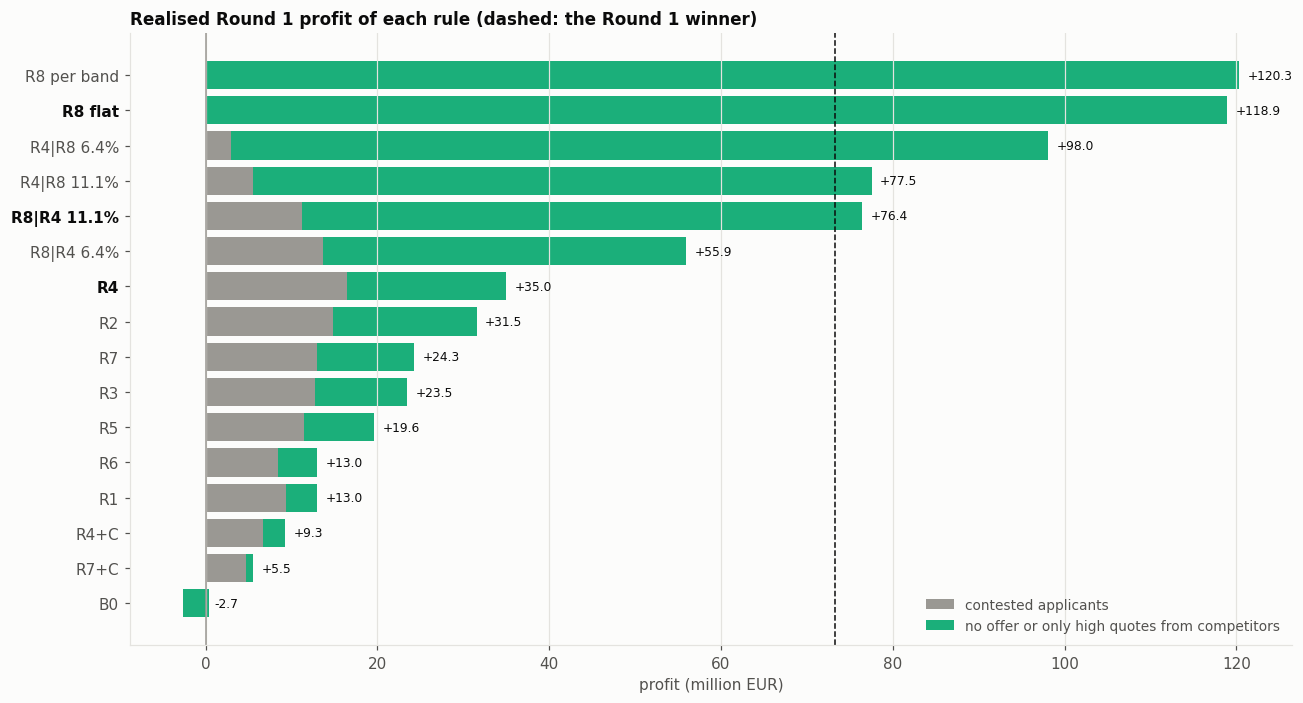

In [11]:
# Every candidate on one table: Part 6 rules, R8, hybrids, and the perfect-foresight ceiling.
SWITCHES = {"6.4%": edges[3], "11.1%": edges[5]}      # 4th and 6th R4 decile edges
new_rates = {
    "R8 flat": rule_high_quote(data, best_flat),
    "R8 per band": rule_band_quotes(data, edges, per_band["best rate"].to_numpy()),
    **{f"R4|R8 {k}": rule_switch(data, rates["R4"], p, best_flat, "above") for k, p in SWITCHES.items()},
    **{f"R8|R4 {k}": rule_switch(data, rates["R4"], p, best_flat, "below") for k, p in SWITCHES.items()},
    "oracle": oracle_rates(data),
}
table_new, profits_new = score_replay(new_rates, data)
table_all = pd.concat([table, table_new])
profits_all = {**profits, **profits_new}
rates_all = {**rates, **new_rates}

HYBRIDS = [f"{h} {k}" for h in ("R4|R8", "R8|R4") for k in SWITCHES]
CANDIDATES = PART6 + ["R8 flat", "R8 per band"] + HYBRIDS
ranked = table_all.loc[CANDIDATES].sort_values("profit", ascending=False)
display(table_all.loc[list(ranked.index) + ["oracle"], cols].style.format(fmt))

fig, ax = plt.subplots(figsize=(12, 6.5))
plot_rule_profits(ranked, ax, highlight=("R4", "R8 flat", "R8|R4 11.1%"), reference=WINNER_PROFIT,
                  title="Realised Round 1 profit of each rule (dashed: the Round 1 winner)")
fig.tight_layout()
save(fig, "fig20_round1_rule_profits.png")
plt.show()

Ranked by realised profit (the hybrids switch at 6.4% or 11.1%, the 4th and 6th R4 decile edges, with
the 89.5% high quote):

| rule | profit | loans | share | avg rate | default rate of loans won |
|---|---|---|---|---|---|
| R8 per band | **€120.3M** | 20,243 | 20.2% | 90.5% | 16.4% |
| R8 flat (89.5%) | €118.9M | 20,328 | 20.3% | 89.5% | 16.4% |
| R4\|R8 6.4% | €98.0M | 38,048 | 38.0% | 43.8% | 10.4% |
| R4\|R8 11.1% | €77.5M | 46,918 | 46.9% | 32.5% | 10.1% |
| R8\|R4 11.1% | €76.4M | 28,978 | 29.0% | 51.4% | 16.9% |
| R8\|R4 6.4% | €55.9M | 37,848 | 37.8% | 35.7% | 15.1% |
| **R4 (submitted)** | **€35.0M** | 55,568 | 55.6% | 21.5% | 11.4% |
| R4+C | €9.3M | 35,808 | 35.8% | 9.9% | 6.4% |
| *Round 1 winner* | *€73.3M* | | | | |
| *perfect foresight (oracle)* | *€282.2M* | 88,675 | 88.7% | 31.8% | 0% |

* **Market share was the wrong target.** R4 had the largest share of any reasonable rule (55.6%) and
  one of the lowest profits per loan (€630). R8 lends to a fifth of the market and earns €5,850 per
  loan.
* **Every high-quote rule beats the winner**, except R8|R4 6.4%. The winner probably exploited part of
  the uncontested pool.
* **The oracle** knows every default and every competitor offer. It bounds what any rule could earn
  (€282M), but it is not attainable.

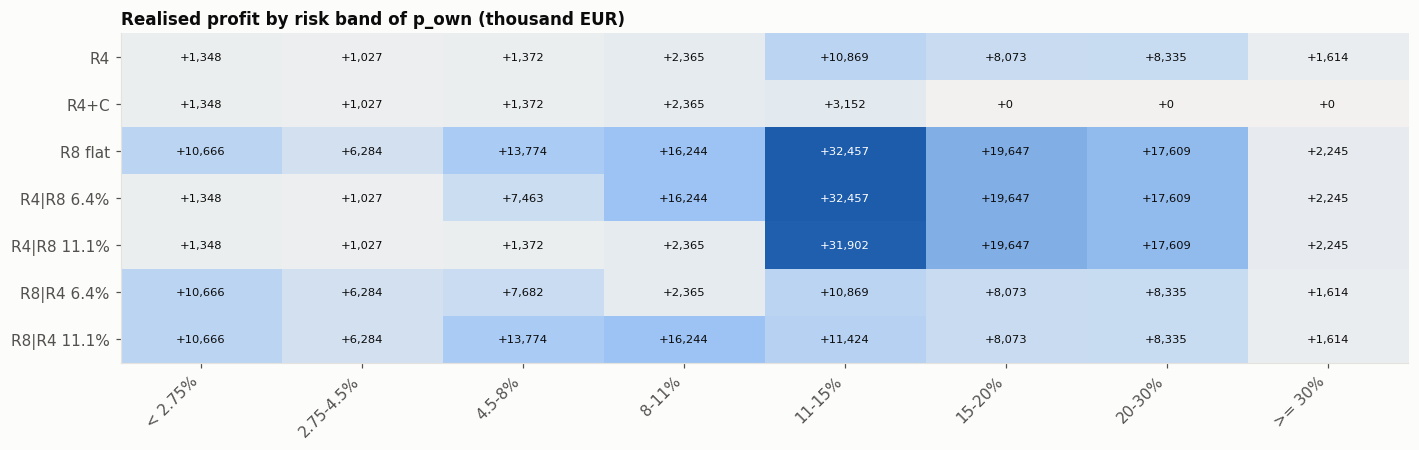

,no competitor offer,only high quotes,contested
rule,,,
R4,"+6,721,385","+11,837,737","+16,445,012"
R4+C,"+1,467,099","+1,113,274","+6,684,981"
R8 flat,"+55,816,750","+62,897,900","+212,200"
R4|R8 6.4%,"+34,823,439","+60,265,234","+2,953,098"
R4|R8 11.1%,"+24,850,007","+47,191,249","+5,474,644"
R8|R4 6.4%,"+27,714,696","+14,470,403","+13,704,113"
R8|R4 11.1%,"+37,688,128","+27,544,388","+11,182,568"


In [12]:
SHOW = ["R4", "R4+C", "R8 flat"] + HYBRIDS
fig, ax = plt.subplots(figsize=(13, 4.2))
pp.plot_heatmap(profit_by_band(profits_all, data).loc[SHOW], ax,
                "Realised profit by risk band of p_own (thousand EUR)")
fig.tight_layout()
plt.show()

split = profit_by_situation({k: profits_all[k] for k in SHOW}, data)
display(split[SITUATIONS].groupby(level="rule", sort=False).sum().style.format("{:+,.0f}"))

**Where each rule earns** (profit by market situation):

| rule | no competitor offer | only high quotes | contested |
|---|---|---|---|
| R4 | €6.7M | €11.8M | €16.4M |
| R8 flat | €55.8M | €62.9M | €0.2M |
| R4\|R8 11.1% | €24.9M | €47.2M | €5.5M |
| R8\|R4 11.1% | €37.7M | €27.5M | €11.2M |

**R8|R4 keeps two thirds of R4's contested profit** and still collects €65M from the uncontested
applicants. R4|R8 does the opposite: it gives up most of R4's contested profit, which sits in the
risky bands.

## 7. Would it survive Round 2? Two stress tests

survival,0%,10%,25%,50%,75%,100%
rule,,,,,,
R4,"+23,561,408","+24,705,681","+26,422,090","+29,282,771","+32,143,453","+35,004,134"
R4+C,"+7,978,833","+8,107,485","+8,300,463","+8,622,094","+8,943,724","+9,265,355"
R8 flat,"+353,915","+12,211,208","+29,997,149","+59,640,382","+89,283,616","+118,926,850"
R4|R8 6.4%,"+3,328,263","+12,799,614","+27,006,640","+50,685,018","+74,363,395","+98,041,772"
R4|R8 11.1%,"+6,354,157","+13,470,331","+24,144,593","+41,935,029","+59,725,464","+77,515,900"
R8|R4 6.4%,"+20,587,060","+24,117,275","+29,412,598","+38,238,136","+47,063,674","+55,889,212"
R8|R4 11.1%,"+17,561,166","+23,446,558","+32,274,646","+46,988,125","+61,701,605","+76,415,084"


,beats R4 if at least this share of the uncontested pool survives
R4+C,never
R8 flat,22%
R4|R8 6.4%,24%
R4|R8 11.1%,29%
R8|R4 6.4%,12%
R8|R4 11.1%,13%


,R8 flat beats R4 if this share survives,"R4 profit, contested","R8 flat profit, uncontested"
< 2.75%,12%,"+1,165,586","+10,666,350"
2.75-4.5%,16%,"+922,601","+6,284,050"
4.5-8%,11%,"+1,368,410","+13,773,500"
8-11%,14%,"+1,829,425","+16,244,500"
11-15%,23%,"+4,685,470","+32,406,550"
15-20%,29%,"+3,154,486","+19,585,150"
20-30%,36%,"+2,925,408","+17,544,050"
>= 30%,53%,"+393,625","+2,210,500"


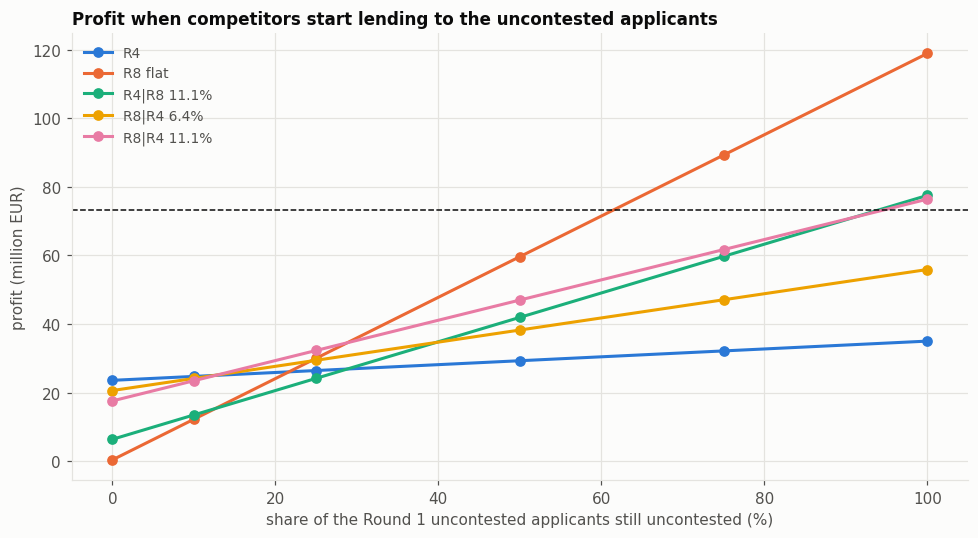

In [13]:
# Stress 1: part of the uncontested pool becomes contested in Round 2.
SURVIVAL = [0.0, 0.1, 0.25, 0.5, 0.75, 1.0]
stress = stress_uncontested(split, SURVIVAL)
display(stress.style.format("{:+,.0f}").format_index("{:.0%}", axis=1))
be_share = pd.Series({r: breakeven_survival(stress, r, "R4") for r in SHOW if r != "R4"},
                     name="beats R4 if at least this share of the uncontested pool survives")
display(be_share.to_frame().style.format("{:.0%}", na_rep="never"))

# The same break-even share band by band: where does the high quote need the least help?
stress_bands = stress_uncontested(split, [0.0, 1.0], by_band=True)
per_band_be = pd.DataFrame({"R8 flat beats R4 if this share survives":
                            [breakeven_survival(stress_bands.xs(b, level="band"), "R8 flat", "R4")
                             for b in BAND_LABELS]}, index=BAND_LABELS)
per_band_be["R4 profit, contested"] = split.loc["R4", "contested"]
per_band_be["R8 flat profit, uncontested"] = (split.loc["R8 flat", SITUATIONS[0]]
                                              + split.loc["R8 flat", SITUATIONS[1]])
display(per_band_be.style.format({"R8 flat beats R4 if this share survives": "{:.0%}",
                                  "R4 profit, contested": "{:+,.0f}",
                                  "R8 flat profit, uncontested": "{:+,.0f}"}, na_rep="never"))

fig, ax = plt.subplots(figsize=(9, 5))
plot_stress(stress, ax, rules=["R4", "R8 flat", "R4|R8 11.1%", "R8|R4 6.4%", "R8|R4 11.1%"],
            reference=WINNER_PROFIT)
fig.tight_layout()
save(fig, "fig21_round1_stress.png")
plt.show()

**Stress 1: the uncontested applicants become contested.** Every team has its diagnostic file and can
see what we see. In Round 2, some of the 20% of applicants nobody competed for will get competitive
offers. For each band, we let only a share $s$ of the uncontested applicants stay uncontested. The
others earn what that rule earned per contested applicant of the same band in Round 1.

| rule | $s = 0$ | $s = 25\%$ | $s = 50\%$ | $s = 100\%$ (Round 1) | beats R4 if $s \ge$ |
|---|---|---|---|---|---|
| R4 | **€23.6M** | €26.4M | €29.3M | €35.0M | — |
| R8 flat | €0.4M | €30.0M | **€59.6M** | **€118.9M** | 22% |
| R4\|R8 11.1% | €6.4M | €24.1M | €41.9M | €77.5M | 29% |
| R8\|R4 6.4% | €20.6M | €29.4M | €38.2M | €55.9M | **12%** |
| R8\|R4 11.1% | €17.6M | **€32.3M** | €47.0M | €76.4M | 13% |

* **R8 flat is all-or-nothing.** If the uncontested pool disappears completely, it earns nothing: it
  wins no contested applicants. It beats R4 as long as at least **22%** of the pool survives.
* **R8|R4 needs only 12–13% of the pool** to beat R4, and it is the best rule at $s = 25\%$. It loses
  only €3–6M against R4 if the pool disappears entirely.
* **R4|R8 is the worst choice when the pool shrinks:** at $s = 0$ it earns €3–6M, against €18–21M
  for R8|R4. It catches up only when most of the pool survives (R4|R8 11.1% passes R8|R4 11.1% above
  $s \approx 90\%$).
* **Per band, the high quote needs the least help on the safe applicants**: 11–16% survival below 11%
  risk, against 23–53% above. There R4's contested margin is thin, and a safe uncontested borrower at
  89.5% earns €8,000–8,800 in expectation. This is why R8|R4 is the robust direction.

In [14]:
# Stress 2: the teams that quoted 91.99% / 97.89% cut their high quote to q (no-offers unchanged).
# Our rates do not depend on the competitors' offers, so the same rates are replayed.
UNDERCUT = [0.95, 0.92, 0.90, 0.88, 0.85, 0.80]
undercut = pd.DataFrame({q: score_replay({r: rates_all[r] for r in SHOW},
                                         undercut_high_quotes(data, q))[0]["profit"]
                         for q in UNDERCUT})
undercut.insert(0, "Round 1", table_all.loc[SHOW, "profit"])
display(undercut.style.format("{:+,.0f}").format_index(lambda q: q if isinstance(q, str) else f"{q:.0%}",
                                                       axis=1))

,Round 1,95%,92%,90%,88%,85%,80%
rule,,,,,,,
R4,"+35,004,134","+34,963,707","+34,919,726","+34,895,265","+34,906,066","+34,900,217","+34,835,437"
R4+C,"+9,265,355","+9,265,355","+9,265,355","+9,265,355","+9,265,355","+9,265,355","+9,265,355"
R8 flat,"+118,926,850","+118,957,400","+118,957,400","+92,784,500","+77,120,300","+55,979,450","+55,979,450"
R4|R8 6.4%,"+98,041,772","+98,072,322","+98,072,322","+72,776,572","+57,904,222","+37,554,172","+37,554,172"
R4|R8 11.1%,"+77,515,900","+77,546,450","+77,546,450","+57,493,600","+46,055,600","+30,321,300","+30,321,300"
R8|R4 6.4%,"+55,889,212","+55,848,785","+55,804,805","+54,903,193","+54,122,144","+53,325,495","+53,260,716"
R8|R4 11.1%,"+76,415,084","+76,374,657","+76,330,676","+70,186,165","+65,970,766","+60,558,367","+60,493,588"


**Stress 2: the high-quote teams cut their quote.** The teams that quoted 91.99% and 97.89% can also see
that the uncontested applicants paid. Here every competitor quote of 90% or more is replaced by $q$,
and no-offers are unchanged:

* **Down to 92%:** nothing changes; our 89.5% still wins.
* **At 90% and 88%:** R8 flat falls to €92.8M and then €77.1M. It now loses the borrowers who prefer
  the competitor.
* **At 85% and below:** R8 flat keeps only the applicants with no competitor offer, **€56.0M**, still
  1.6 times R4.
* **R8|R4 11.1% loses the least:** from €76.4M to €60.5M at 85%, where it becomes the best rule.
  R4 barely moves (€34.8–35.0M):
  it rarely quotes that high.

This assumes our quote stays at 89.5%. In Round 2 the high quote is itself a price war among teams.
On an applicant who gets only high quotes, the lowest effective high quote wins, and the 2-point
preference of our type-3 borrowers helps us. The level of our high quote has to be re-tuned against
Part 10's empirical competitor scenario (Part 11).

## 8. Conclusions

**What happened in Round 1**

1. **The replay is exact** (100% of acceptances, profit to the euro), so every number above is a true
   counterfactual on the Round 1 market.
2. **R4 was the right choice among the rules we had.** It was the best of the ten Part 6 rules
   (€35.0M). Its high quotes on risky applicants earned €25.7M more than R4+C's cutoff, which is the
   option Part 7 bet on.
3. **But our candidate set missed the real market.** **20% of applicants were uncontested** (no
   competitor offer, or only fixed quotes of 91.99% / 97.89%). Each of them accepts any rate up to
   100%. None of our Part 7 scenarios had high fixed quotes; only S_R4C had a large uncontested pool.
4. **R4 left about €84M on the table** against a flat 89.5% quote, nearly all of it in that pool: R4
   earned €18.6M from the uncontested applicants, R8 €118.7M. In the contested market, better margins
   would have added only about €4M.
5. **Model quality was not the problem.** $p_{own}$ was calibrated on all applicants (9.96% vs
   9.95%). The +0.95-point gap on our loans is the winner's curse. The uncontested applicants are
   only 1–1.6 points riskier than predicted, which is irrelevant at a 90% rate. Luck of the borrower
   types was worth €36k.
6. **Market share was the wrong target.** We had the largest share (55.6%) at €630 per loan. R8 would
   have had 20% at €5,850 per loan.

**For Round 2:**

7. **The gain depends on the uncontested pool surviving**, and every team now knows it exists.
   Part 10 should measure that pool per competitor behaviour (no offer, high quote, pricing curve)
   and per risk band.
8. **The robust hybrid is R8|R4: a high quote on safe applicants, R4 (or better margins) on risky
   ones.** It beats R4 as soon as 13% of the uncontested pool survives. It loses at most €6M if the
   pool disappears completely, and it loses the least when the high quotes are undercut to 85%.
   The reverse hybrid R4|R8, which the plan suggested, collapses when the pool shrinks.
9. **The high quote's level is the key parameter, and it is strategic:** 89.5% was tuned to the
   91.99% quote of one team. In Part 11 it should be re-tuned against undercutting competitors.
10. **The contested margins of R4 were too low**, especially below 8.7% risk and in the 8.7–11%
    decile (+€4.3M in hindsight). This is worth re-tuning in Part 11.